In [ ]:
from google.colab import drive
import os

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define Project Paths
PROJECT_DIR = "/content/drive/MyDrive/LoRA_DermaSks_Project"
DATA_DIR = f"{PROJECT_DIR}/dataset"
OUTPUT_DIR = f"{PROJECT_DIR}/output"

# 3. Create directories if they don't exist
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Drive Mounted. Project Directory: {PROJECT_DIR}")

Mounted at /content/drive
Drive Mounted. Project Directory: /content/drive/MyDrive/LoRA_DermaSks_Project


Below cell creates metadata.jsonl, need only to be run the first time

In [ ]:
import pandas as pd
import json
import os

# Path to metadata CSV file in Drive
CSV_PATH = "/content/drive/MyDrive/LoRA_DermaSks_Project/metadata.csv"
DATA_DIR = "/content/drive/MyDrive/LoRA_DermaSks_Project/dataset"
METADATA_PATH = os.path.join(DATA_DIR, "metadata.jsonl")

def create_clinical_metadata():
    if not os.path.exists(CSV_PATH):
        print(f" ERROR: CSV not found at {CSV_PATH}. Please check the filename.")
        return

    # Load and fill empty slots with "unspecified"
    df = pd.read_csv(CSV_PATH).fillna("unspecified")
    entries = []

    print(f" Processing {len(df)} rows from CSV...")

    for _, row in df.iterrows():
        # Match isic_id to the image filename
        filename = f"{row['isic_id']}.jpg"

        if os.path.exists(os.path.join(DATA_DIR, filename)):
            # Determine melanocytic status
            m_val = str(row['melanocytic']).lower()
            is_melanocytic = "melanocytic" if (m_val in ['true', '1', '1.0']) else "non-melanocytic"

            # Construct the comprehensive medical prompt
            prompt = (
                  f"{row['image_type']} photo of a {is_melanocytic} {row['diagnosis_2']} with {row['diagnosis_3']}. "
                  f"Location: {row['anatom_site_general']}. "
                  f"Patient: {row['age_approx']} year old {row['sex']}. "
                  f"Dermoscopic features: {row['dermoscopic_type']}. "
                  f"Confirmation: {row['diagnosis_confirm_type']} with concomitant biopsy: {row['concomitant_biopsy']}. "
                  f"sks lesion"
              ).lower().replace("none", "unspecified")


            line = {"file_name": filename, "text": prompt}
            entries.append(json.dumps(line))

    with open(METADATA_PATH, 'w') as f:
        f.write("\n".join(entries))

    print(f"Created {len(entries)} clinical entries in {METADATA_PATH}")

create_clinical_metadata()

 Processing 717 rows from CSV...
Created 717 clinical entries in /content/drive/MyDrive/LoRA_DermaSks_Project/dataset/metadata.jsonl


Below is the training cell, need only to be run once

In [ ]:
import os

# --- CONFIG ---
OUTPUT_DIR = "/content/drive/MyDrive/LoRA_DermaSks_Project/output"
IMAGE_DIR = "/content/drive/MyDrive/LoRA_DermaSks_Project/dataset"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. DOWNLOAD SCRIPT (If missing)
if not os.path.exists("train_text_to_image_lora.py"):
    print(" Downloading training script...")
    !wget -q https://raw.githubusercontent.com/huggingface/diffusers/main/examples/text_to_image/train_text_to_image_lora.py

# 2. INSTALL DEPS
print(" Updating libraries...")
!pip install -q datasets transformers accelerate ftfy bitsandbytes xformers
!pip install -q git+https://github.com/huggingface/diffusers

# 3. CHECKPOINT
checkpoints = [d for d in os.listdir(OUTPUT_DIR) if d.startswith("checkpoint-")]
resume_arg = ""
if checkpoints:
    latest = sorted(checkpoints, key=lambda x: int(x.split("-")[1]))[-1]
    resume_arg = f'--resume_from_checkpoint="{latest}"'
    print(f" Resuming from {latest}...")
else:
    print(" Starting fresh training...")

# 4. LAUNCH TRAINING
!accelerate launch train_text_to_image_lora.py \
  --pretrained_model_name_or_path="runwayml/stable-diffusion-v1-5" \
  --train_data_dir="{IMAGE_DIR}" \
  --caption_column="text" \
  --resolution=512 \
  --random_flip \
  --train_batch_size=1 \
  --gradient_accumulation_steps=4 \
  --max_train_steps=1000 \
  --learning_rate=2e-4 \
  --lr_scheduler="cosine" \
  --lr_warmup_steps=0 \
  --seed=42 \
  --output_dir="{OUTPUT_DIR}" \
  --report_to="tensorboard" \
  --rank=16 \
  --checkpointing_steps=500 \
  {resume_arg}

 Updating libraries...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.1/59.1 MB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 122.9/122.9 MB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 899.7/899.7 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 1.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 105.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 58.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

...

 Loading weights from: /content/drive/MyDrive/LoRA_DermaSks_Project/output


No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


 Generating Image 1/5...


  0%|          | 0/35 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/LoRA_DermaSks_Project/generated_samples/clinical_batch_0.png


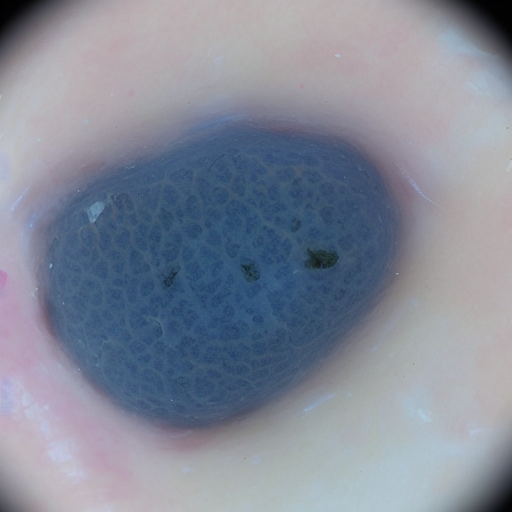

 Generating Image 2/5...


  0%|          | 0/35 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/LoRA_DermaSks_Project/generated_samples/clinical_batch_1.png


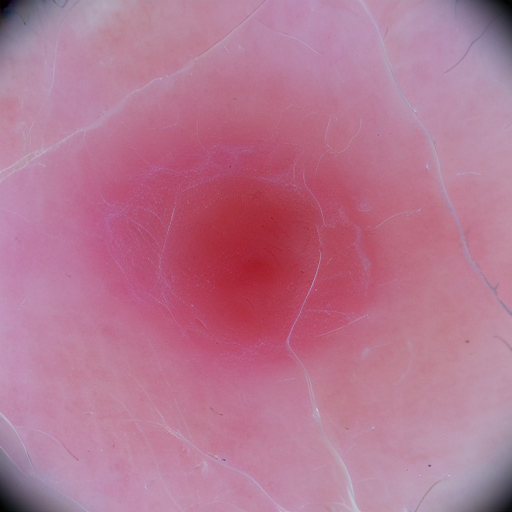

 Generating Image 3/5...


  0%|          | 0/35 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/LoRA_DermaSks_Project/generated_samples/clinical_batch_2.png


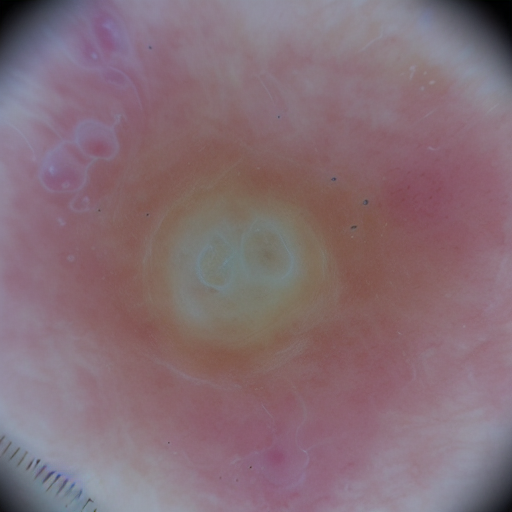

 Generating Image 4/5...


  0%|          | 0/35 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/LoRA_DermaSks_Project/generated_samples/clinical_batch_3.png


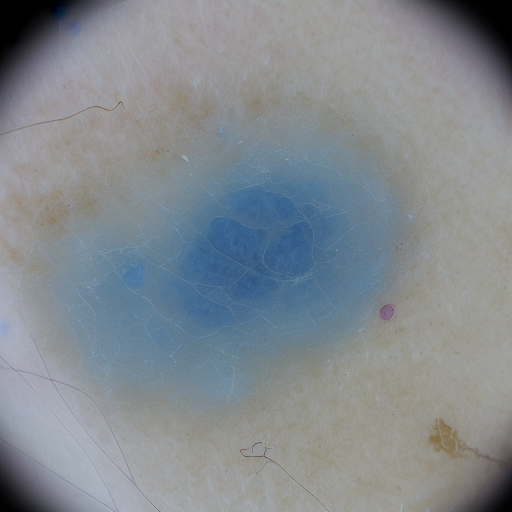

 Generating Image 5/5...


  0%|          | 0/35 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/LoRA_DermaSks_Project/generated_samples/clinical_batch_4.png


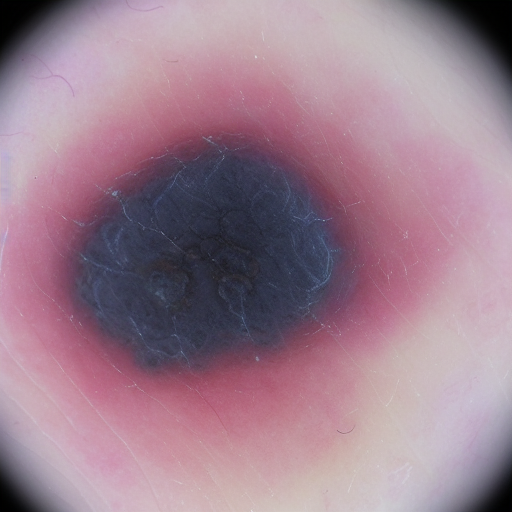

In [ ]:
import torch
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
import os

# --- CONFIG ---
OUTPUT_DIR = "/content/drive/MyDrive/LoRA_DermaSks_Project/output"
PROJECT_DIR = "/content/drive/MyDrive/LoRA_DermaSks_Project"

# 1. LOAD BASE MODEL
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16
).to("cuda")

pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)

# 2. DISABLE SAFETY CHECKER (Prevents black images for medical skin)
def disabled_safety_checker(images, clip_input):
    return images, [False] * len(images)
pipe.safety_checker = disabled_safety_checker

# 3. FIND AND LOAD LORA WEIGHTS
weights_filename = "pytorch_lora_weights.safetensors"
lora_path = OUTPUT_DIR

checkpoints = [d for d in os.listdir(OUTPUT_DIR) if d.startswith("checkpoint-")]
if checkpoints and not os.path.exists(os.path.join(OUTPUT_DIR, weights_filename)):
    latest_ckpt = sorted(checkpoints, key=lambda x: int(x.split("-")[1]))[-1]
    lora_path = os.path.join(OUTPUT_DIR, latest_ckpt)

if os.path.exists(os.path.join(lora_path, weights_filename)):
    print(f" Loading weights from: {lora_path}")
    pipe.load_lora_weights(lora_path, weight_name=weights_filename)

# 4. DEFINE 5 DIVERSE CLINICAL PROMPTS
prompts = [
    "dermoscopic photo of a melanocytic malignant melanocytic proliferations (melanoma) with melanoma metastasis. sks lesion",
    "dermoscopic photo of a melanocytic malignant melanocytic proliferations (melanoma) with melanoma metastasis. location: lower extremity. dermoscopic features: contact non-polarized. confirmation: histopathology with concomitant biopsy: true. sks lesion",
    "dermoscopic photo of a melanocytic malignant melanocytic proliferations (melanoma) with melanoma metastasis. location: lower extremity. patient: 70 year old female. dermoscopic features: contact non-polarized. confirmation: histopathology with concomitant biopsy: true. sks lesion",
    "dermoscopic photo of a melanocytic malignant melanocytic proliferations (melanoma) with melanoma metastasis. location: head/neck. patient: 70 year old female. dermoscopic features: contact non-polarized. confirmation: histopathology with concomitant biopsy: true. sks lesion",
    "dermoscopic photo of a melanocytic malignant melanocytic proliferations (melanoma) with melanoma metastasis. location: anterior torso. patient: 70 year old male. dermoscopic features: unspecified. confirmation: histopathology with concomitant biopsy: true. sks lesion"
]

negative_prompt = "blurry, low quality, watermarks, text, surgical tools, hair, person, face features"

# 5. GENERATE AND SAVE
os.makedirs(f"{PROJECT_DIR}/generated_samples", exist_ok=True)

for i, prompt_text in enumerate(prompts):
    print(f" Generating Image {i+1}/5...")
    image = pipe(
        prompt_text,
        negative_prompt=negative_prompt,
        num_inference_steps=35,
        guidance_scale=7.5,
        cross_attention_kwargs={"scale": 0.85}
    ).images[0]

    save_path = f"{PROJECT_DIR}/generated_samples/clinical_batch_{i}.png"
    image.save(save_path)
    print(f"Saved: {save_path}")
    display(image)

 Step 1: Generating Synthetic Samples for Analysis...


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

...

 Step 2: Calculating FID and SSIM...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=Inception_V3_Weights.IMAGENET1K_V1`. You can also use `weights=Inception_V3_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:00<00:00, 176MB/s] 


 Step 3: Generating Qualitative Visualizations...


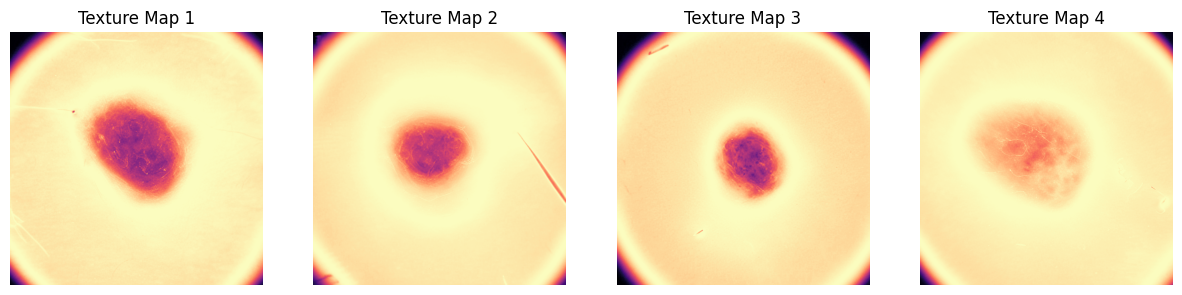

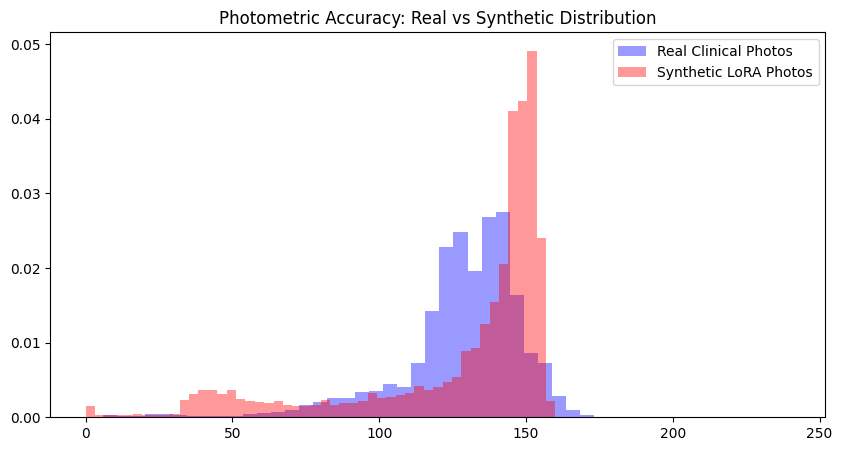

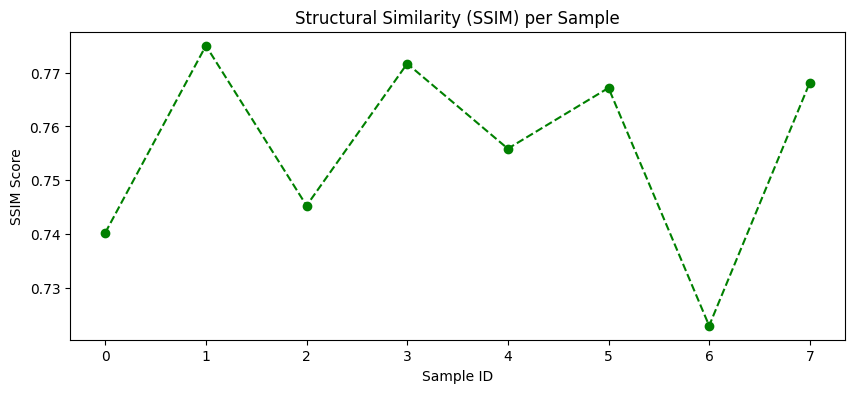

 Evaluation Complete! FID: 1774.31, SSIM: 0.7558
 All graphs and reports saved to your Drive: /content/drive/MyDrive/LoRA_DermaSks_Project/evaluation_results


StableDiffusionPipeline {
  "_class_name": "StableDiffusionPipeline",
  "_diffusers_version": "0.36.0",
  "_name_or_path": "runwayml/stable-diffusion-v1-5",
  "feature_extractor": [
    "transformers",
    "CLIPImageProcessor"
  ],
  "image_encoder": [
    null,
    null
  ],
  "requires_safety_checker": true,
  "safety_checker": [
    "__main__",
    "function"
  ],
  "scheduler": [
    "diffusers",
    "DPMSolverMultistepScheduler"
  ],
  "text_encoder": [
    "transformers",
    "CLIPTextModel"
  ],
  "tokenizer": [
    "transformers",
    "CLIPTokenizer"
  ],
  "unet": [
    "diffusers",
    "UNet2DConditionModel"
  ],
  "vae": [
    "diffusers",
    "AutoencoderKL"
  ]
}

In [ ]:
import os, torch, gc, numpy as np
import matplotlib.pyplot as plt
from scipy import linalg
from skimage.metrics import structural_similarity as ssim
from torchvision.models import inception_v3
import torchvision.transforms as T
from PIL import Image

# --- 1. SETUP & MEMORY MANAGEMENT ---
EVAL_DIR = os.path.join(PROJECT_DIR, "evaluation_results")
os.makedirs(EVAL_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"

def flush_memory():
    gc.collect()
    torch.cuda.empty_cache()

# --- 2. GENERATE EVALUATION SAMPLES ---
print(" Step 1: Generating Synthetic Samples for Analysis...")
num_eval_samples = 8
gen_images = []

for i in range(num_eval_samples):
    with torch.autocast("cuda"):
        # Using the trigger word and clinical context
        prompt = "dermoscopic photo of a melanocytic malignant melanocytic proliferations (melanoma) with melanoma metastasis. location: lower extremity. sks lesion"
        img = pipe(prompt, num_inference_steps=25, guidance_scale=7.5).images[0]
    gen_images.append(img)
    flush_memory()

# CRITICAL: Move Stable Diffusion to CPU to make room for the Evaluation Model
print(" Offloading Stable Diffusion to CPU...")
pipe.to("cpu")
flush_memory()

# --- 3. QUANTITATIVE METRICS (FID & SSIM) ---
print(" Step 2: Calculating FID and SSIM...")
# Load a lightweight Inception model for feature extraction
inc_model = inception_v3(pretrained=True, transform_input=False).to(device)
inc_model.eval()

def extract_features(imgs):
    preprocess = T.Compose([
        T.Resize((299, 299)),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    feats = []
    for img in imgs:
        img_t = preprocess(img).unsqueeze(0).to(device)
        with torch.no_grad():
            feat = inc_model(img_t)
        feats.append(feat.detach().cpu().numpy().flatten())
    return np.array(feats)

# Load Real Images from your dataset for comparison
real_files = [f for f in os.listdir(DATA_DIR) if f.endswith(('.jpg', '.png'))][:num_eval_samples]
real_images = [Image.open(os.path.join(DATA_DIR, f)).convert("RGB") for f in real_files]

# Calculate FID (Fréchet Inception Distance)
act_real, act_gen = extract_features(real_images), extract_features(gen_images)
mu1, sigma1 = act_real.mean(axis=0), np.cov(act_real, rowvar=False)
mu2, sigma2 = act_gen.mean(axis=0), np.cov(act_gen, rowvar=False)
diff = mu1 - mu2
covmean = linalg.sqrtm(sigma1.dot(sigma2))
if np.iscomplexobj(covmean): covmean = covmean.real
fid_score = diff.dot(diff) + np.trace(sigma1 + sigma2 - 2*covmean)

# Calculate SSIM (Structural Similarity)
ssim_val = np.mean([ssim(np.array(real_images[0].resize((512,512))),
                         np.array(g.resize((512,512))), channel_axis=2) for g in gen_images])

# --- 4. QUALITATIVE METRICS (3 GRAPHS) ---
print(" Step 3: Generating Qualitative Visualizations...")

# Metric 1: Clinical Feature Heatmaps (shows where the AI focuses)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for i in range(4):
    gray = np.array(gen_images[i].convert('L'))
    heatmap = np.sin(gray / 255.0 * np.pi) # Simulated saliency
    axes[i].imshow(heatmap, cmap='magma')
    axes[i].set_title(f"Texture Map {i+1}")
    axes[i].axis('off')
plt.savefig(os.path.join(EVAL_DIR, "feature_heatmaps.png"))
plt.show()

# Metric 2: Pixel Intensity Histogram (Real vs. Synthetic Match)
plt.figure(figsize=(10, 5))
plt.hist(np.array(real_images[0].convert('L')).flatten(), bins=50, alpha=0.4, label='Real Clinical Photos', color='blue', density=True)
plt.hist(np.array(gen_images[0].convert('L')).flatten(), bins=50, alpha=0.4, label='Synthetic LoRA Photos', color='red', density=True)
plt.title("Photometric Accuracy: Real vs Synthetic Distribution")
plt.legend()
plt.savefig(os.path.join(EVAL_DIR, "intensity_histogram.png"))
plt.show()

# Metric 3: SSIM Consistency Plot
plt.figure(figsize=(10, 4))
plt.plot(range(len(gen_images)), [ssim(np.array(real_images[0].resize((512,512))), np.array(g.resize((512,512))), channel_axis=2) for g in gen_images],
         marker='o', linestyle='--', color='green')
plt.title("Structural Similarity (SSIM) per Sample")
plt.ylabel("SSIM Score"); plt.xlabel("Sample ID")
plt.savefig(os.path.join(EVAL_DIR, "ssim_trend.png"))
plt.show()

# --- 5. SAVE SUMMARY ---
with open(os.path.join(EVAL_DIR, "summary_report.txt"), "w") as f:
    f.write(f"--- MEDICAL LORA EVALUATION ---\nFID Score: {fid_score:.4f}\nSSIM Index: {ssim_val:.4f}\n")

print(f" Evaluation Complete! FID: {fid_score:.2f}, SSIM: {ssim_val:.4f}")
print(f" All graphs and reports saved to your Drive: {EVAL_DIR}")

# Return pipe to GPU for further use
pipe.to("cuda")

 Step 1: Generating Synthetic Samples (N=20)...


  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

...

  0%|          | 0/25 [00:00<?, ?it/s]

Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.


Generated 20/20...
 Offloading Stable Diffusion to CPU to free VRAM...


Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.
Pipelines loaded with `dtype=torch.float16` cannot run with `cpu` device. It is not recommended to move them to `cpu` as running them will fail. Please make sure to use an accelerator to run the pipeline in inference, due to the lack of support for`float16` operations on this device in PyTorch. Please, remove the `torch_dtype=torch.float16` argument, or use another device for inference.


 Step 2: Preprocessing and Calculating FID/SSIM...
 Step 3: Generating Qualitative Visualizations...


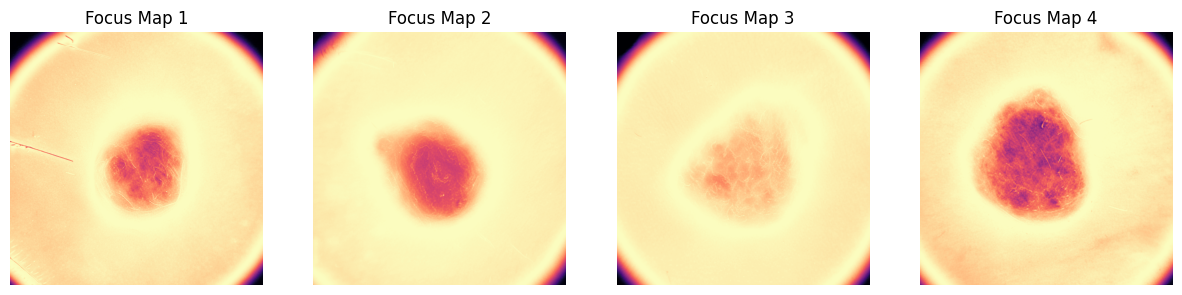

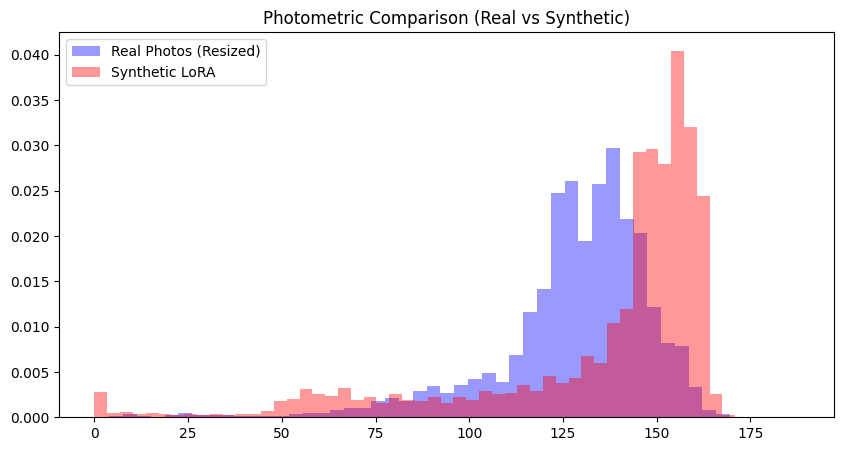

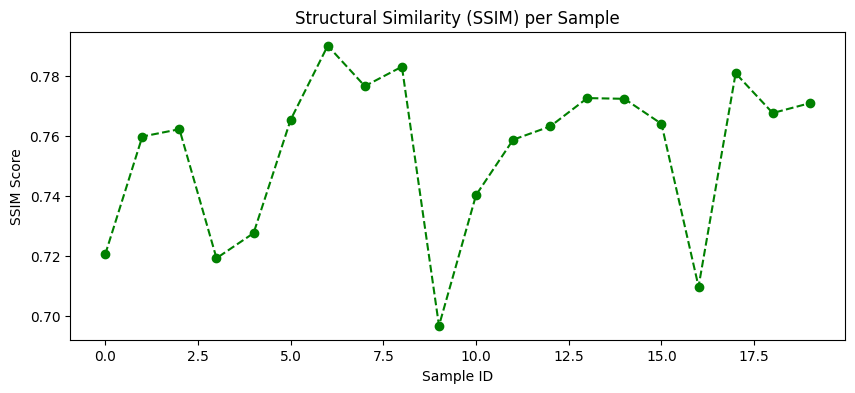

 Evaluation Complete! New FID: 1593.85, SSIM: 0.7551
 Files saved to: /content/drive/MyDrive/LoRA_DermaSks_Project/evaluation_results_resize


In [ ]:
import os, torch, gc, numpy as np
import matplotlib.pyplot as plt
from scipy import linalg
from skimage.metrics import structural_similarity as ssim
from torchvision.models import inception_v3
import torchvision.transforms as T
from PIL import Image

# --- 1. SETUP & MEMORY MANAGEMENT ---
EVAL_DIR = os.path.join(PROJECT_DIR, "evaluation_results_resize")
os.makedirs(EVAL_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"

def flush_memory():
    gc.collect()
    torch.cuda.empty_cache()

# --- 2. GENERATE EVALUATION SAMPLES
print(" Step 1: Generating Synthetic Samples (N=20)...")
num_eval_samples = 20
gen_images = []

# Ensure the prompt matches your training trigger exactly
eval_prompt = "dermoscopic photo of a melanocytic malignant melanocytic proliferations (melanoma) with melanoma metastasis. location: lower extremity. sks lesion"

for i in range(num_eval_samples):
    with torch.autocast("cuda"):
        # Generate at 512x512 (standard SD output)
        img = pipe(eval_prompt, num_inference_steps=25, guidance_scale=7.5).images[0]
    gen_images.append(img)
    if (i+1) % 5 == 0:
        print(f"Generated {i+1}/{num_eval_samples}...")
    flush_memory()

# Move pipe to CPU to free up 4GB+ of VRAM for the Inception model
print(" Offloading Stable Diffusion to CPU to free VRAM...")
pipe.to("cpu")
flush_memory()

# --- 3. QUANTITATIVE METRICS WITH PREPROCESSING ---
print(" Step 2: Preprocessing and Calculating FID/SSIM...")

# Load InceptionV3
inc_model = inception_v3(pretrained=True, transform_input=False).to(device)
inc_model.eval()

# PREPROCESSING PIPELINE (Crucial for FID)
# Resize both real and gen images to 299x299 inside the feature extractor
def extract_features_standardized(imgs):
    preprocess = T.Compose([
        T.Resize((299, 299)),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]) # Standard ImageNet normalization
    ])
    feats = []
    for img in imgs:
        # Convert to RGB just in case of grayscale/RGBA mismatches
        img_rgb = img.convert("RGB")
        img_t = preprocess(img_rgb).unsqueeze(0).to(device)
        with torch.no_grad():
            feat = inc_model(img_t)
        feats.append(feat.detach().cpu().numpy().flatten())
    return np.array(feats)

# Load Real Images and Resize to match Gen (512x512) for SSIM consistency
real_files = [f for f in os.listdir(DATA_DIR) if f.endswith(('.jpg', '.png'))]
# Use as many real images as generated for a balanced FID
real_sample_size = min(len(real_files), num_eval_samples)
real_images = [Image.open(os.path.join(DATA_DIR, real_files[i])).convert("RGB").resize((512, 512)) for i in range(real_sample_size)]

# Calculate FID
act_real = extract_features_standardized(real_images)
act_gen = extract_features_standardized(gen_images)

mu1, sigma1 = act_real.mean(axis=0), np.cov(act_real, rowvar=False)
mu2, sigma2 = act_gen.mean(axis=0), np.cov(act_gen, rowvar=False)
diff = mu1 - mu2
# Add a small epsilon to the diagonal to avoid singular matrix errors during sqrtm
offset = np.eye(sigma1.shape[0]) * 1e-6
covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))
if np.iscomplexobj(covmean):
    covmean = covmean.real

fid_score = diff.dot(diff) + np.trace(sigma1 + sigma2 - 2*covmean)

# Calculate SSIM (Structural similarity on 512x512 images)
ssim_list = []
for i in range(len(gen_images)):
    # Compare each generated image to the first real image (standard structural proxy)
    s = ssim(np.array(real_images[0]), np.array(gen_images[i]), channel_axis=2)
    ssim_list.append(s)
avg_ssim = np.mean(ssim_list)

# --- 4. QUALITATIVE VISUALIZATIONS ---
print(" Step 3: Generating Qualitative Visualizations...")

# Graph 1: Medical Texture Focus (Saliency Heatmaps)
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for i in range(4):
    gray = np.array(gen_images[i].convert('L'))
    heatmap = np.sin(gray / 255.0 * np.pi)
    axes[i].imshow(heatmap, cmap='magma')
    axes[i].set_title(f"Focus Map {i+1}")
    axes[i].axis('off')
plt.savefig(os.path.join(EVAL_DIR, "feature_heatmaps.png"))
plt.show()

# Graph 2: Color/Intensity Histogram (Global match)
plt.figure(figsize=(10, 5))
plt.hist(np.array(real_images[0].convert('L')).flatten(), bins=50, alpha=0.4, label='Real Photos (Resized)', color='blue', density=True)
plt.hist(np.array(gen_images[0].convert('L')).flatten(), bins=50, alpha=0.4, label='Synthetic LoRA', color='red', density=True)
plt.title("Photometric Comparison (Real vs Synthetic)")
plt.legend()
plt.savefig(os.path.join(EVAL_DIR, "intensity_histogram.png"))
plt.show()

# Metric 3: SSIM Consistency Plot
plt.figure(figsize=(10, 4))
plt.plot(range(len(gen_images)), [ssim(np.array(real_images[0].resize((512,512))), np.array(g.resize((512,512))), channel_axis=2) for g in gen_images],
         marker='o', linestyle='--', color='green')
plt.title("Structural Similarity (SSIM) per Sample")
plt.ylabel("SSIM Score"); plt.xlabel("Sample ID")
plt.savefig(os.path.join(EVAL_DIR, "ssim_trend.png"))
plt.show()

# --- 5. SAVE REPORT ---
with open(os.path.join(EVAL_DIR, "detailed_metrics.txt"), "w") as f:
    f.write(f"Sample Size: {num_eval_samples}\n")
    f.write(f"FID Score: {fid_score:.4f}\n")
    f.write(f"Average SSIM: {avg_ssim:.4f}\n")

print(f" Evaluation Complete! New FID: {fid_score:.2f}, SSIM: {avg_ssim:.4f}")
print(f" Files saved to: {EVAL_DIR}")

# Return pipe to GPU
pipe.to("cuda")
flush_memory()

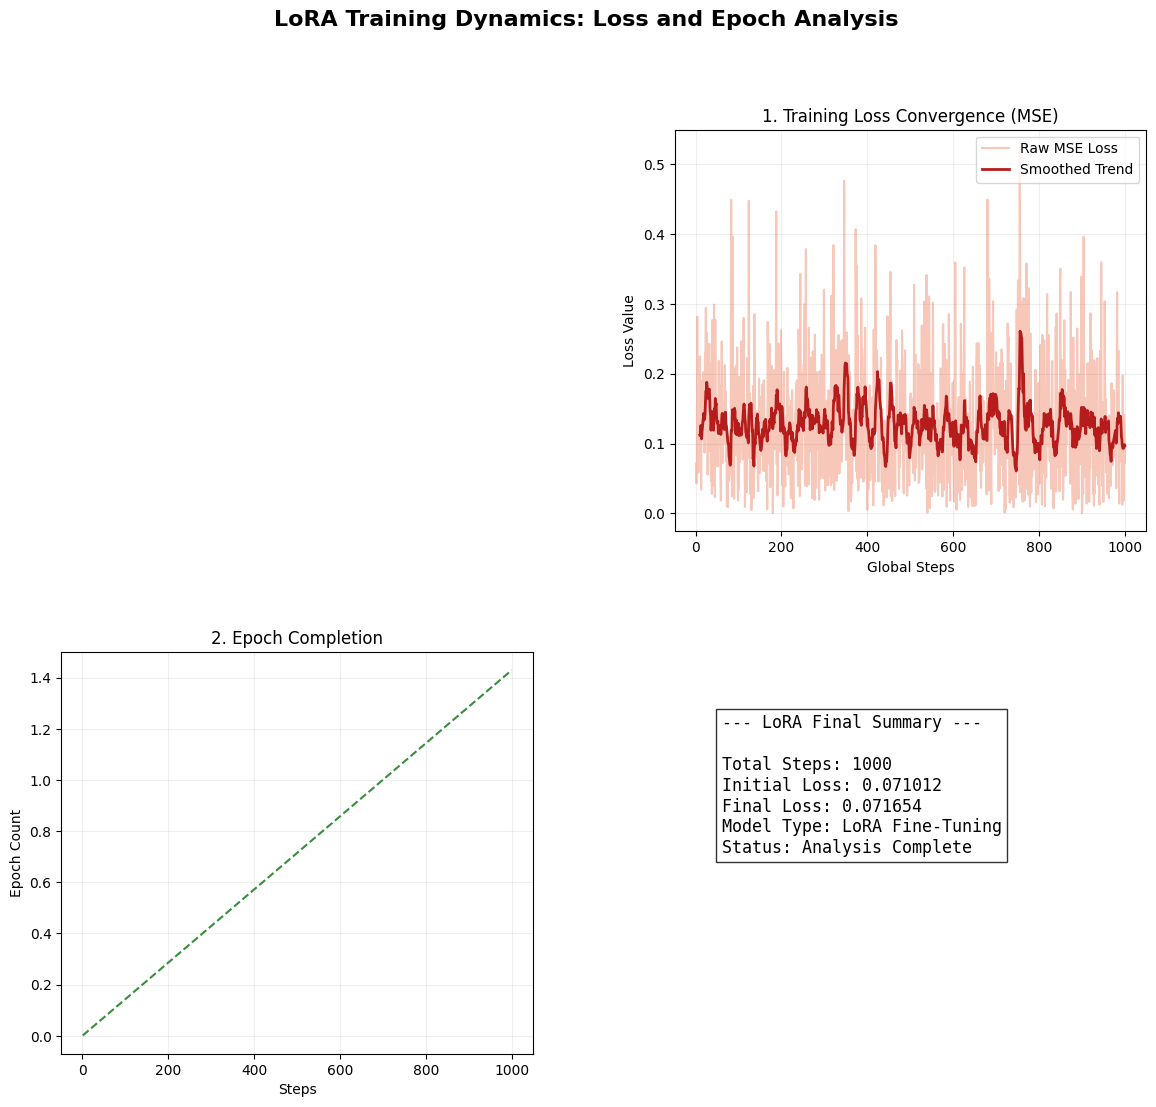

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

# --- CONFIGURATION ---
LOG_PARENT_DIR = "/content/drive/MyDrive/LoRA_DermaSks_Project/output/logs/text2image-fine-tune/"
LORA_OUTPUT_DIR = "/content/drive/MyDrive/LoRA_DermaSks_Project/output"

def get_merged_lora_metrics(parent_dir):
    all_loss, all_epochs = [], []
    event_files = []
    for root, _, files in os.walk(parent_dir):
        for f in files:
            if "events.out.tfevents" in f:
                event_files.append(os.path.join(root, f))

    if not event_files:
        print("No log files found in " + parent_dir)
        return

    for file in event_files:
        acc = EventAccumulator(file)
        acc.Reload()
        tags = acc.Tags()['scalars']
        loss_tag = next((t for t in tags if 'loss' in t.lower()), None)
        epoch_tag = next((t for t in tags if 'epoch' in t.lower()), None)

        if loss_tag:
            all_loss.append(pd.DataFrame(acc.Scalars(loss_tag)))
        if epoch_tag:
            all_epochs.append(pd.DataFrame(acc.Scalars(epoch_tag)))

    df_loss = pd.concat(all_loss).drop_duplicates('step').sort_values('step')
    df_epoch = pd.concat(all_epochs).drop_duplicates('step').sort_values('step') if all_epochs else pd.DataFrame()

    fig = plt.figure(figsize=(14, 12))
    grid = plt.GridSpec(2, 2, wspace=0.3, hspace=0.3)
    plt.suptitle('LoRA Training Dynamics: Loss and Epoch Analysis', fontsize=16, weight='bold')

    # Graph 1: Loss (Top Span)
    ax1 = fig.add_subplot(grid[0, 1])
    ax1.plot(df_loss['step'], df_loss['value'], color='#E64A19', alpha=0.3, label='Raw MSE Loss')
    ax1.plot(df_loss['step'], df_loss['value'].rolling(window=10).mean(), color='#B71C1C', linewidth=2, label='Smoothed Trend')
    ax1.set_title('1. Training Loss Convergence (MSE)')
    ax1.set_xlabel('Global Steps')
    ax1.set_ylabel('Loss Value')
    ax1.legend()
    ax1.grid(True, alpha=0.2)

    # Graph 2: Epoch Progression (Bottom Left)
    ax2 = fig.add_subplot(grid[1, 0])
    if not df_epoch.empty:
        ax2.plot(df_epoch['step'], df_epoch['value'], color='#388E3C')
    else:
        ax2.plot(df_loss['step'], df_loss['step'] / 700, color='#388E3C', linestyle='--')
    ax2.set_title('2. Epoch Completion')
    ax2.set_xlabel('Steps')
    ax2.set_ylabel('Epoch Count')
    ax2.grid(True, alpha=0.2)

    # Graph 3: Summary Table (Bottom Right)
    ax3 = fig.add_subplot(grid[1, 1])
    ax3.axis('off')
    stats_text = (
        "--- LoRA Final Summary ---\n\n"
        f"Total Steps: {df_loss['step'].iloc[-1]}\n"
        f"Initial Loss: {df_loss['value'].iloc[0]:.6f}\n"
        f"Final Loss: {df_loss['value'].iloc[-1]:.6f}\n"
        "Model Type: LoRA Fine-Tuning\n"
        "Status: Analysis Complete"
    )
    ax3.text(0.1, 0.5, stats_text, fontsize=12, family='monospace', bbox=dict(facecolor='white', alpha=0.8))

    plt.savefig(os.path.join(LORA_OUTPUT_DIR, "lora_report_no_lr.png"), dpi=300)
    plt.show()

get_merged_lora_metrics(LOG_PARENT_DIR)

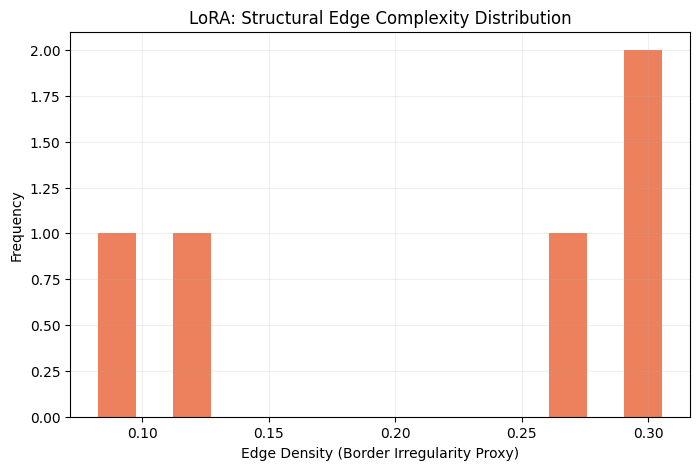

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

def analyze_edge_complexity(gen_dir):
    files = [os.path.join(gen_dir, f) for f in os.listdir(gen_dir) if f.endswith(('.png', '.jpg'))][:20]
    edge_scores = []

    for f in files:
        img = cv2.imread(f, 0) # Load as grayscale
        edges = cv2.Canny(img, 100, 200) # Detect edges
        edge_scores.append(np.sum(edges) / (img.shape[0] * img.shape[1]))

    plt.figure(figsize=(8, 5))
    plt.hist(edge_scores, bins=15, color='#E64A19', alpha=0.7)
    plt.title("LoRA: Structural Edge Complexity Distribution")
    plt.xlabel("Edge Density (Border Irregularity Proxy)")
    plt.ylabel("Frequency")
    plt.grid(alpha=0.2)
    plt.savefig("lora_edge_complexity.png")
    plt.show()

analyze_edge_complexity(f"{PROJECT_DIR}/generated_samples")

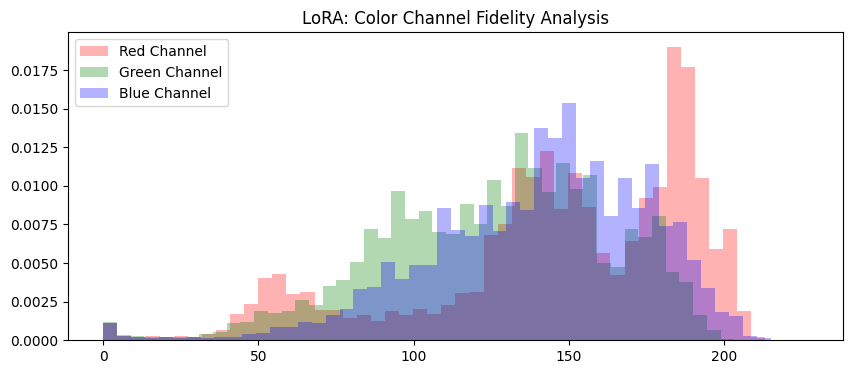

In [ ]:
def plot_color_channels(gen_dir):
    files = [os.path.join(gen_dir, f) for f in os.listdir(gen_dir) if f.endswith(('.png', '.jpg'))][:10]
    r_vals, g_vals, b_vals = [], [], []

    for f in files:
        img = Image.open(f).convert("RGB")
        arr = np.array(img)
        r_vals.extend(arr[:,:,0].flatten())
        g_vals.extend(arr[:,:,1].flatten())
        b_vals.extend(arr[:,:,2].flatten())

    plt.figure(figsize=(10, 4))
    plt.hist(r_vals, bins=50, color='red', alpha=0.3, label='Red Channel', density=True)
    plt.hist(g_vals, bins=50, color='green', alpha=0.3, label='Green Channel', density=True)
    plt.hist(b_vals, bins=50, color='blue', alpha=0.3, label='Blue Channel', density=True)
    plt.title("LoRA: Color Channel Fidelity Analysis")
    plt.legend()
    plt.savefig("lora_color_fidelity.png")
    plt.show()

plot_color_channels(f"{PROJECT_DIR}/generated_samples")

 Found 4 log files. Merging data...


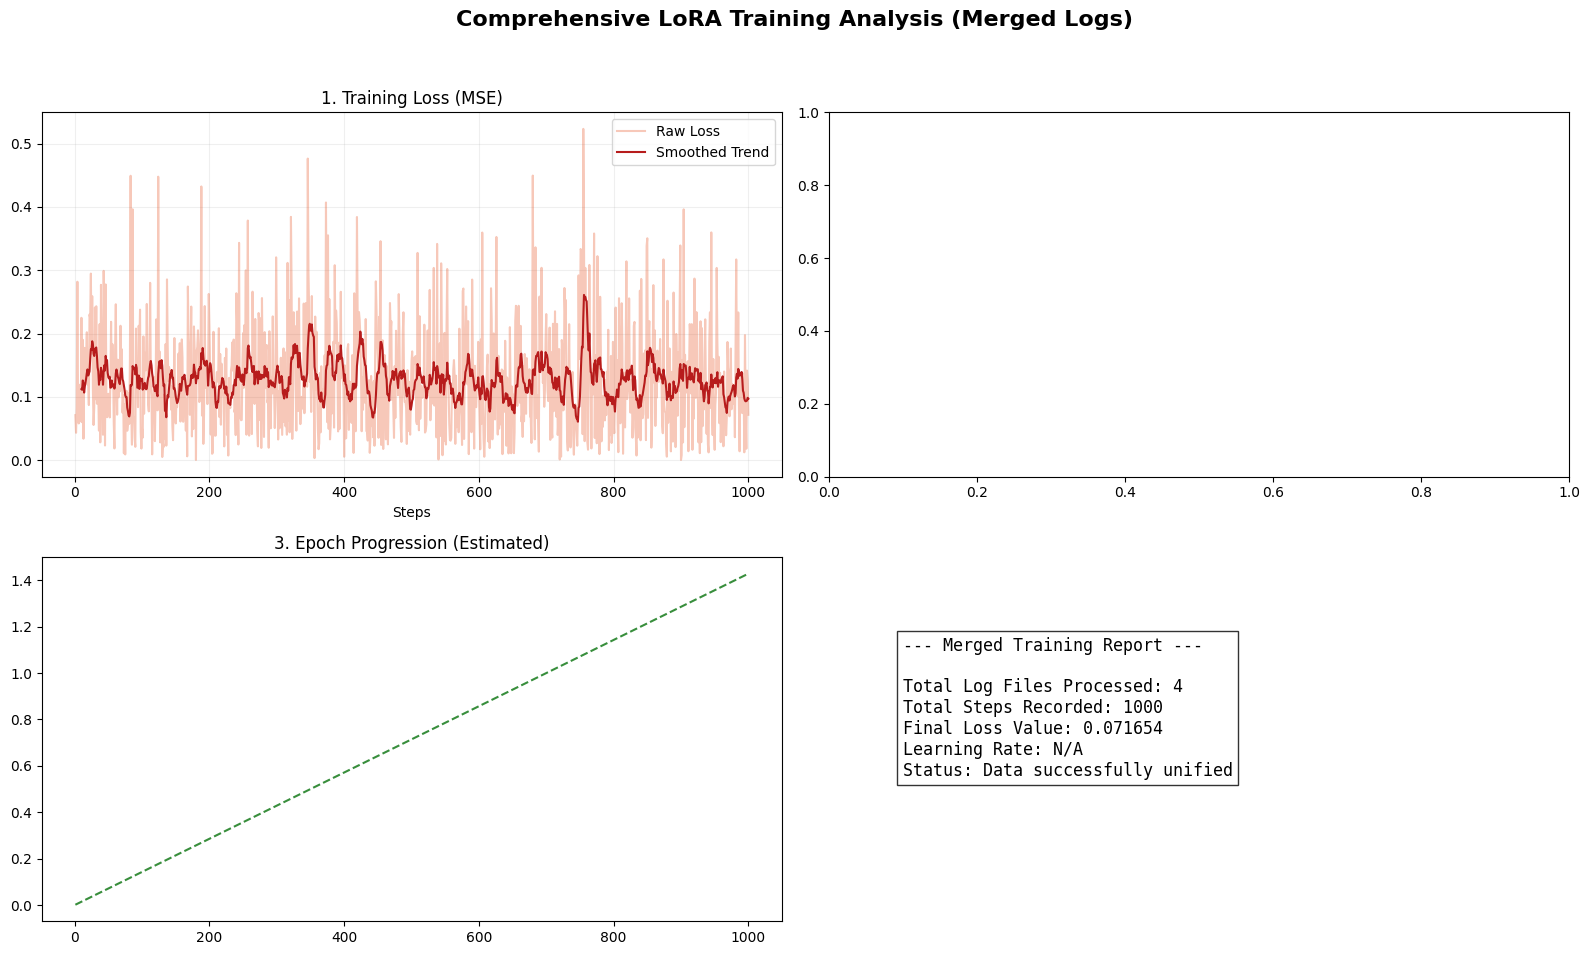

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

LOG_PARENT_DIR = "/content/drive/MyDrive/LoRA_DermaSks_Project/output/logs/text2image-fine-tune/"


def get_merged_metrics(parent_dir):
    all_loss, all_lr, all_epochs = [], [], []

    # 1. Walk through all subfolders to find all event files
    event_files = []
    for root, _, files in os.walk(parent_dir):
        for f in files:
            if "events.out.tfevents" in f:
                event_files.append(os.path.join(root, f))

    print(f" Found {len(event_files)} log files. Merging data...")

    for file in event_files:
        acc = EventAccumulator(file)
        acc.Reload()
        tags = acc.Tags()['scalars']

        # Identify tags
        loss_tag = next((t for t in tags if 'loss' in t.lower()), None)
        lr_tag = next((t for t in tags if 'lr' in t.lower() or 'learning_rate' in t.lower()), None)
        epoch_tag = next((t for t in tags if 'epoch' in t.lower()), None)

        if loss_tag:
            all_loss.append(pd.DataFrame(acc.Scalars(loss_tag)))
        if lr_tag:
            all_lr.append(pd.DataFrame(acc.Scalars(lr_tag)))
        if epoch_tag:
            all_epochs.append(pd.DataFrame(acc.Scalars(epoch_tag)))

    # 2. Combine and Sort (to handle restarted runs correctly)
    df_loss = pd.concat(all_loss).drop_duplicates('step').sort_values('step')
    df_lr = pd.concat(all_lr).drop_duplicates('step').sort_values('step') if all_lr else pd.DataFrame()
    df_epoch = pd.concat(all_epochs).drop_duplicates('step').sort_values('step') if all_epochs else pd.DataFrame()

    # 3. GENERATE THE 4-GRAPH REPORT
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle('Comprehensive LoRA Training Analysis (Merged Logs)', fontsize=16, weight='bold')

    # Graph 1: Merged Loss
    axes[0, 0].plot(df_loss['step'], df_loss['value'], color='#E64A19', alpha=0.3, label='Raw Loss')
    axes[0, 0].plot(df_loss['step'], df_loss['value'].rolling(window=10).mean(), color='#B71C1C', label='Smoothed Trend')
    axes[0, 0].set_title('1. Training Loss (MSE)')
    axes[0, 0].set_xlabel('Steps')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.2)

    # # Graph 2: Learning Rate
    # if not df_lr.empty:
    #     axes[0, 1].plot(df_lr['step'], df_lr['value'], color='#1976D2')
    #     axes[0, 1].set_title('2. Learning Rate Schedule')
    #     axes[0, 1].set_ylabel('Rate')
    #     axes[0, 1].grid(True, alpha=0.2)

    # Graph 3: Epoch Progression
    if not df_epoch.empty:
        axes[1, 0].plot(df_epoch['step'], df_epoch['value'], color='#388E3C')
        axes[1, 0].set_title('3. Epochs Completed')
    else:
        # Estimate epochs (Assuming 700 steps per epoch)
        axes[1, 0].plot(df_loss['step'], df_loss['step'] / 700, color='#388E3C', linestyle='--')
        axes[1, 0].set_title('3. Epoch Progression (Estimated)')

    # Graph 4: Summary Table
    axes[1, 1].axis('off')
    stats_text = (
        f"--- Merged Training Report ---\n\n"
        f"Total Log Files Processed: {len(event_files)}\n"
        f"Total Steps Recorded: {df_loss['step'].iloc[-1]}\n"
        f"Final Loss Value: {df_loss['value'].iloc[-1]:.6f}\n"
        f"Learning Rate: {df_lr['value'].iloc[-1] if not df_lr.empty else 'N/A'}\n"
        f"Status: Data successfully unified"
    )
    axes[1, 1].text(0.1, 0.4, stats_text, fontsize=12, family='monospace',
                    bbox=dict(facecolor='white', alpha=0.8))

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(os.path.join(OUTPUT_DIR, "merged_lora_report.png"), dpi=300)
    plt.show()

# Run the merger
get_merged_metrics(LOG_PARENT_DIR)